GOOGLE PLAY STORE ANALYSIS BY MOHAMMED INABAH KHAN

1. INSTALLING DEPENDENCIES

In [ ]:
!pip install -q "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn plotly

2. IMPORTING LIBRARIES

In [18]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from kagglehub import KaggleDatasetAdapter
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

3. LOADING THE DATASETS FROM KAGGLE

In [19]:
DATASET = "lava18/google-play-store-apps"

# Main Google Play Store app dataset
apps_df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    "googleplaystore.csv"
)

# User reviews dataset
reviews_df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    "googleplaystore_user_reviews.csv"
)

print("Apps dataset shape:", apps_df.shape)
print("Reviews dataset shape:", reviews_df.shape)

print("\nFirst 5 apps:")
display(apps_df.head())

print("\nFirst 5 reviews:")
display(reviews_df.head())

/tmp/ipykernel_2064/212158865.py:4: DeprecationWarning:

Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.



100%|██████████| 312k/312k [00:00<00:00, 63.1MB/s]

Extracting zip of googleplaystore.csv...



/tmp/ipykernel_2064/212158865.py:11: DeprecationWarning:

Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.



Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)

First 5 apps:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



First 5 reviews:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
4,10 Best Foods for You,Best idea us,Positive,1.00,0.30


4. UNDERSTANDING THE STRUCTURE

In [20]:
print("APP DATASET INFORMATION")
apps_df.info()

print("\nREVIEW DATASET INFORMATION")
reviews_df.info()

print("\nApp columns:")
print(apps_df.columns.tolist())

print("\nReview columns:")
print(reviews_df.columns.tolist())

print("\nNumerical summary:")
display(apps_df.describe(include="all").T)

APP DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

REVIEW DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 # 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,"9,367.00",NaN,NaN,NaN,4.19,0.54,1.00,4.00,4.30,4.50,19.00
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


5. CLEANING COLUMN NAMES AND INSPECTING DATA QUALITY

In [21]:
# Standardize column names
apps_df.columns = apps_df.columns.str.strip()
reviews_df.columns = reviews_df.columns.str.strip()

# Check missing values
print("Missing values in apps dataset:")
display(apps_df.isnull().sum().sort_values(ascending=False))

print("\nMissing values in reviews dataset:")
display(reviews_df.isnull().sum().sort_values(ascending=False))

# Check duplicates before removing anything
print("\nExact duplicate app rows:", apps_df.duplicated().sum())
print("Duplicate app names:", apps_df["App"].duplicated().sum())

print("\nExact duplicate review rows:", reviews_df.duplicated().sum())

# Remove exact duplicate rows
apps_df = apps_df.drop_duplicates().copy()
reviews_df = reviews_df.drop_duplicates().copy()

# Remove rows with missing essential identifiers
apps_df = apps_df.dropna(subset=["App", "Category"]).copy()
reviews_df = reviews_df.dropna(subset=["App"]).copy()

# Remove malformed category records where Category looks like a date
bad_category = pd.to_datetime(
    apps_df["Category"], errors="coerce"
).notna()

print("Malformed category rows removed:", bad_category.sum())
apps_df = apps_df.loc[~bad_category].copy()

print("Apps shape after basic cleaning:", apps_df.shape)
print("Reviews shape after basic cleaning:", reviews_df.shape)

Missing values in apps dataset:


,0
Rating,1474
Current Ver,8
Android Ver,3
Content Rating,1
Type,1
Size,0
Reviews,0
Category,0
App,0
Price,0



Missing values in reviews dataset:


,0
Translated_Review,26868
Sentiment_Polarity,26863
Sentiment,26863
Sentiment_Subjectivity,26863
App,0



Exact duplicate app rows: 483
Duplicate app names: 1181

Exact duplicate review rows: 33616
Malformed category rows removed: 0
Apps shape after basic cleaning: (10358, 13)
Reviews shape after basic cleaning: (30679, 5)


/tmp/ipykernel_2064/1066175714.py:27: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



6. CLEANING AND CONVERTING THE NUMERIC COLUMNS

In [22]:
# Convert rating and review counts to numeric
apps_df["Rating"] = pd.to_numeric(apps_df["Rating"], errors="coerce")
apps_df["Reviews"] = pd.to_numeric(apps_df["Reviews"], errors="coerce")

# Clean install counts, e.g. "1,000+" -> 1000
apps_df["Installs"] = (
    apps_df["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.strip()
)

apps_df["Installs"] = pd.to_numeric(
    apps_df["Installs"], errors="coerce"
)

# Clean prices, e.g. "$4.99" -> 4.99
apps_df["Price"] = (
    apps_df["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.strip()
)

apps_df["Price"] = pd.to_numeric(
    apps_df["Price"], errors="coerce"
)

# Convert app sizes to megabytes
def size_to_mb(value):
    value = str(value).strip().lower()

    if value in ["nan", "none", "varies with device", ""]:
        return np.nan

    try:
        if value.endswith("k"):
            return float(value[:-1]) / 1024
        elif value.endswith("m"):
            return float(value[:-1])
        elif value.endswith("g"):
            return float(value[:-1]) * 1024
        else:
            return float(value)
    except ValueError:
        return np.nan

apps_df["Size_MB"] = apps_df["Size"].apply(size_to_mb)

# Normalize the free/paid field
apps_df["Type"] = apps_df["Type"].astype(str).str.strip().str.title()

# Valid rating range is 1 to 5
apps_df.loc[~apps_df["Rating"].between(1, 5), "Rating"] = np.nan

print("Cleaned numeric columns:")
display(apps_df[["App", "Rating", "Reviews", "Size_MB", "Installs", "Type", "Price"]].head())

print("\nRemaining missing values:")
display(apps_df[["Rating", "Reviews", "Size_MB", "Installs", "Type", "Price"]].isnull().sum())

Cleaned numeric columns:


,App,Rating,Reviews,Size_MB,Installs,Type,Price
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.10,159.00,19.00,"10,000.00",Free,0.00
1,Coloring book moana,3.90,967.00,14.00,"500,000.00",Free,0.00
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.70,"87,510.00",8.70,"5,000,000.00",Free,0.00
3,Sketch - Draw & Paint,4.50,"215,644.00",25.00,"50,000,000.00",Free,0.00
4,Pixel Draw - Number Art Coloring Book,4.30,967.00,2.80,"100,000.00",Free,0.00



Remaining missing values:


,0
Rating,1466
Reviews,1
Size_MB,1527
Installs,1
Type,0
Price,1


7. EXPLORING APP CATEGORIES

Top 10 categories by number of apps:


,App Count
Category,
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408
PRODUCTIVITY,407
PERSONALIZATION,388
LIFESTYLE,373
COMMUNICATION,366


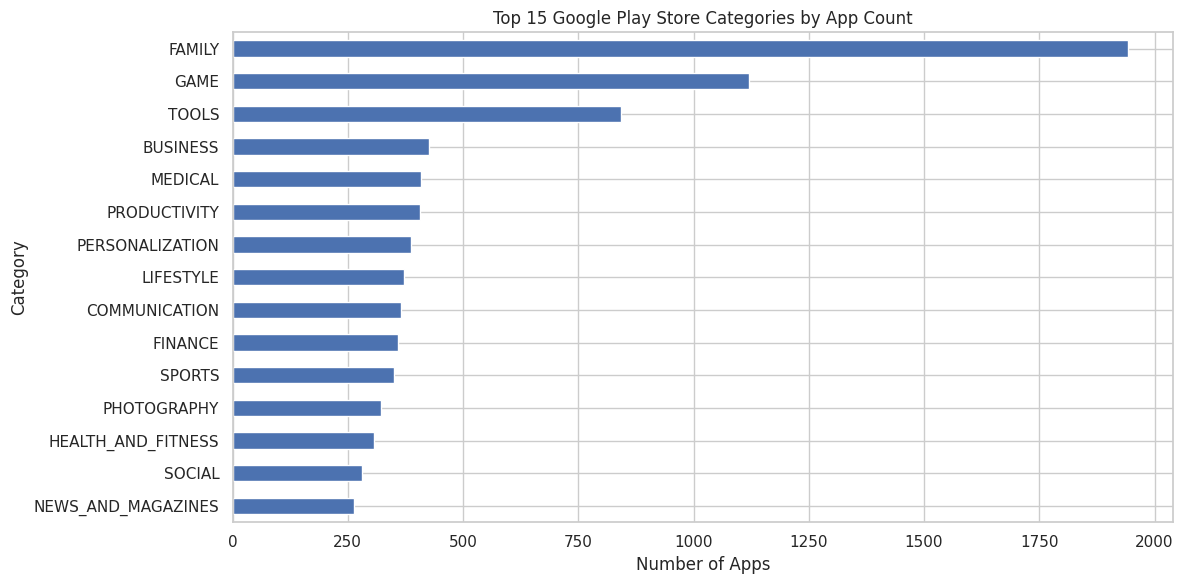

In [23]:
category_counts = apps_df["Category"].value_counts()

print("Top 10 categories by number of apps:")
display(category_counts.head(10).rename("App Count").to_frame())

plt.figure(figsize=(12, 6))
category_counts.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Google Play Store Categories by App Count")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

8. ANALYSING APP REVIEWS

Overall rating statistics:


,Rating
count,"8,892.00"
mean,4.19
std,0.52
min,1.00
25%,4.00
50%,4.30
75%,4.50
max,5.00


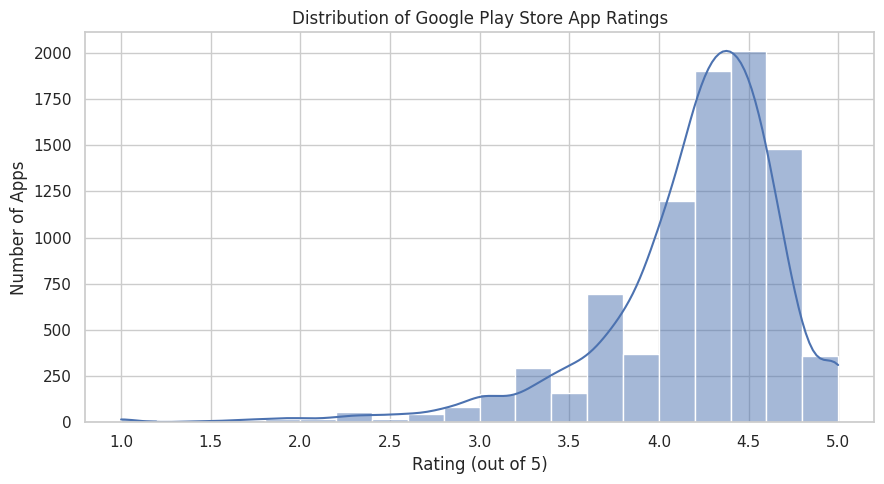

Top 10 categories by average rating:


,Average Rating,Median Rating,Rated Apps
Category,,,
EVENTS,4.44,4.50,45
EDUCATION,4.38,4.40,129
ART_AND_DESIGN,4.36,4.40,62
BOOKS_AND_REFERENCE,4.35,4.50,177
PERSONALIZATION,4.33,4.40,310
PARENTING,4.30,4.40,50
GAME,4.28,4.30,1074
BEAUTY,4.28,4.30,42
HEALTH_AND_FITNESS,4.26,4.50,262


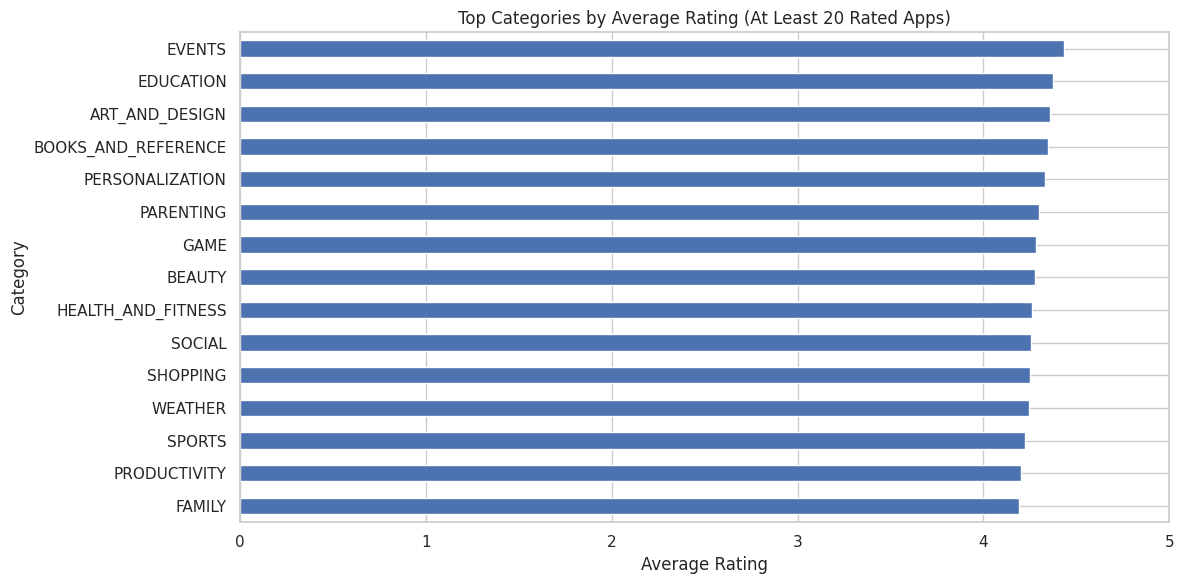

In [24]:
print("Overall rating statistics:")
display(apps_df["Rating"].describe().to_frame())

plt.figure(figsize=(9, 5))
sns.histplot(apps_df["Rating"].dropna(), bins=20, kde=True)
plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating (out of 5)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

# Average rating by category
category_ratings = (
    apps_df.groupby("Category")["Rating"]
    .agg(["mean", "median", "count"])
    .sort_values("mean", ascending=False)
)

category_ratings.columns = ["Average Rating", "Median Rating", "Rated Apps"]

print("Top 10 categories by average rating:")
display(category_ratings.head(10).round(2))

# Require a reasonable minimum number of rated apps for comparison
reliable_categories = category_ratings[
    category_ratings["Rated Apps"] >= 20
].sort_values("Average Rating", ascending=False)

plt.figure(figsize=(12, 6))
reliable_categories["Average Rating"].head(15).sort_values().plot(kind="barh")
plt.title("Top Categories by Average Rating (At Least 20 Rated Apps)")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

9. INVESTIGATING APP SIZE VS INSTALLS

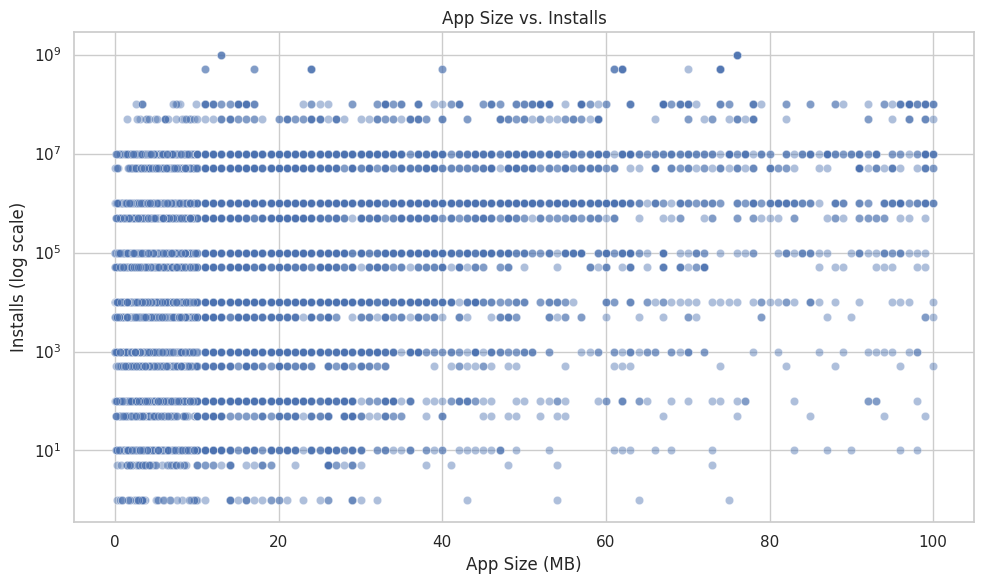

Spearman correlation between app size and installs: 0.342


In [25]:
size_installs = apps_df.dropna(subset=["Size_MB", "Installs"]).copy()
size_installs = size_installs[
    (size_installs["Size_MB"] > 0) &
    (size_installs["Installs"] > 0)
]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=size_installs,
    x="Size_MB",
    y="Installs",
    alpha=0.45
)
plt.yscale("log")
plt.title("App Size vs. Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Installs (log scale)")
plt.tight_layout()
plt.show()

print(
    "Spearman correlation between app size and installs:",
    size_installs["Size_MB"].corr(
        size_installs["Installs"], method="spearman"
    ).round(3)
)

10. COMPARING FREE VS PAID APPS

Free vs Paid comparison:


,App_Count,Average_Rating,Median_Rating,Median_Installs,Average_Price
Type,,,,,
Free,9591,4.18,4.30,"100,000.00",0.00
Paid,765,4.26,4.40,"1,000.00",13.96


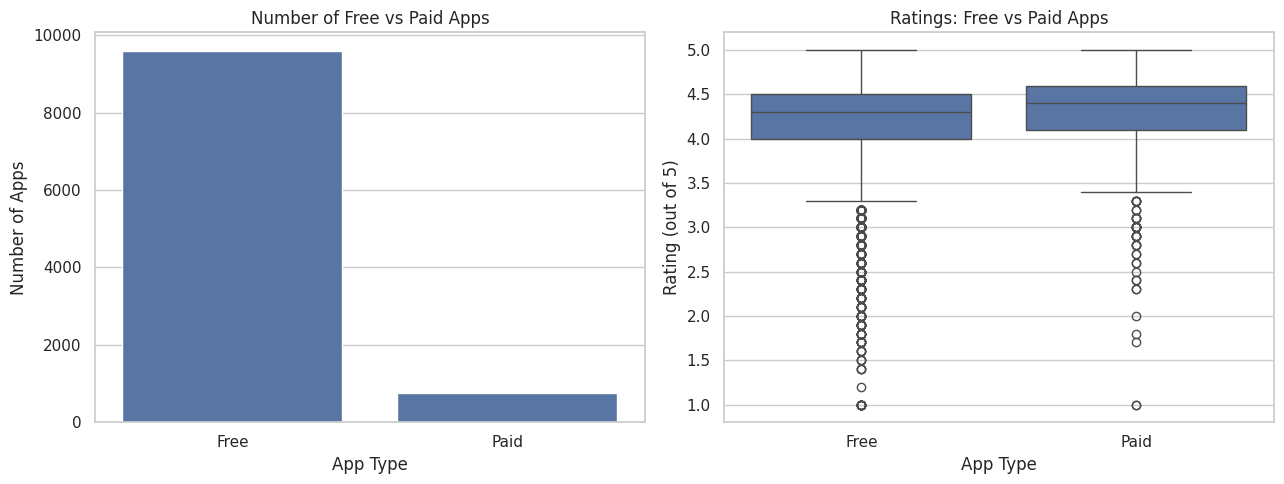

In [26]:
type_df = apps_df[apps_df["Type"].isin(["Free", "Paid"])].copy()

type_summary = type_df.groupby("Type").agg(
    App_Count=("App", "count"),
    Average_Rating=("Rating", "mean"),
    Median_Rating=("Rating", "median"),
    Median_Installs=("Installs", "median"),
    Average_Price=("Price", "mean")
)

print("Free vs Paid comparison:")
display(type_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=type_df, x="Type", ax=axes[0])
axes[0].set_title("Number of Free vs Paid Apps")
axes[0].set_xlabel("App Type")
axes[0].set_ylabel("Number of Apps")

sns.boxplot(data=type_df, x="Type", y="Rating", ax=axes[1])
axes[1].set_title("Ratings: Free vs Paid Apps")
axes[1].set_xlabel("App Type")
axes[1].set_ylabel("Rating (out of 5)")

plt.tight_layout()
plt.show()

11. EXAMINING PAID APP PRICES

Number of paid apps: 765
Price summary:


,Price
count,765.00
mean,13.96
std,58.41
min,0.99
25%,1.49
50%,2.99
75%,4.99
max,400.00


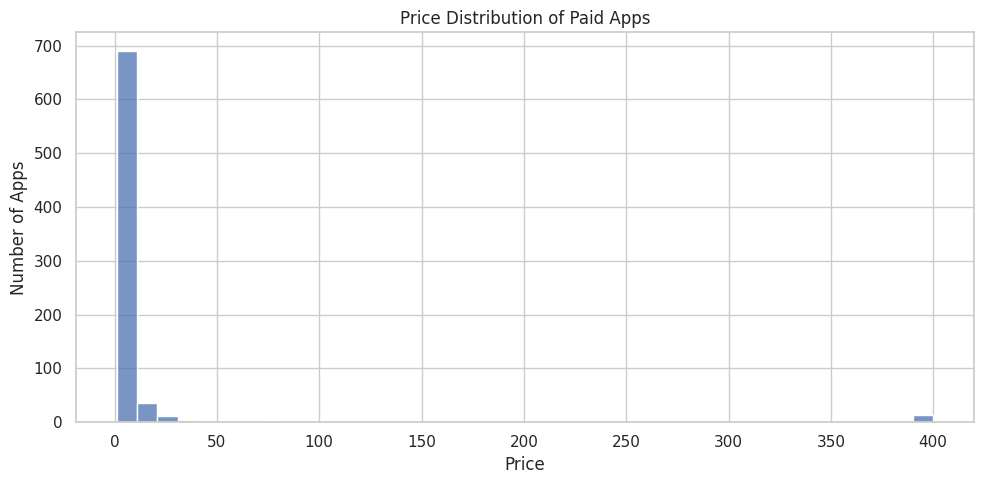

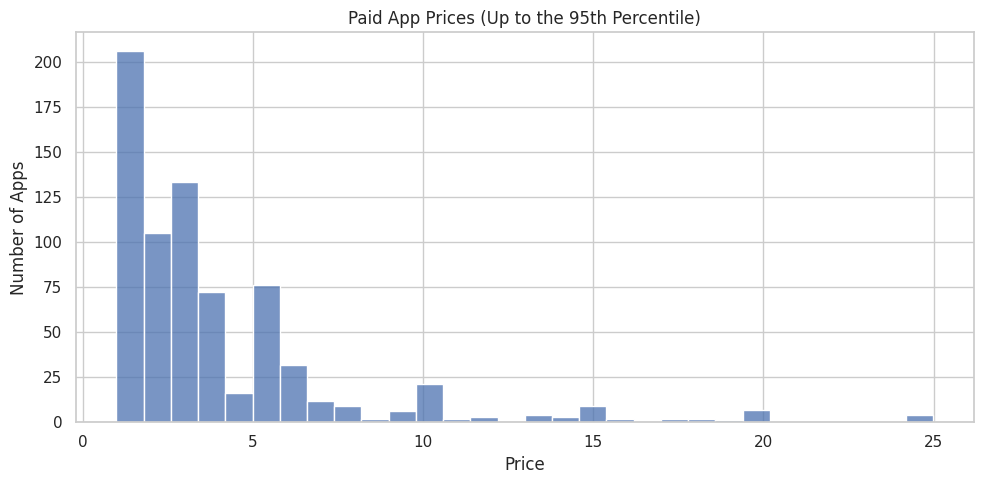

In [27]:
paid_df = apps_df[
    (apps_df["Type"] == "Paid") &
    (apps_df["Price"] > 0)
].copy()

print("Number of paid apps:", len(paid_df))
print("Price summary:")
display(paid_df["Price"].describe().to_frame())

plt.figure(figsize=(10, 5))
sns.histplot(paid_df["Price"], bins=40)
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

# A zoomed-in view helps when a few apps have very high prices
price_95 = paid_df["Price"].quantile(0.95)
paid_zoom = paid_df[paid_df["Price"] <= price_95]

plt.figure(figsize=(10, 5))
sns.histplot(paid_zoom["Price"], bins=30)
plt.title("Paid App Prices (Up to the 95th Percentile)")
plt.xlabel("Price")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

12. ESTIMATING REVENUE BY CATEGORY

Top categories by estimated revenue proxy:


,Estimated Revenue Proxy,Median App Estimate,Paid App Count
Category,,,
FAMILY,"185,780,335.36","14,950.00",187
LIFESTYLE,"57,583,939.40","19,950.00",19
GAME,"40,987,636.85","49,900.00",83
FINANCE,"25,726,678.98","29,900.00",17
PHOTOGRAPHY,"8,942,767.70","17,425.00",20
MEDICAL,"8,456,535.67","7,742.50",84
PERSONALIZATION,"7,786,947.56",990.00,82
TOOLS,"5,464,820.59","2,740.00",78
SPORTS,"4,706,211.95","3,490.00",24


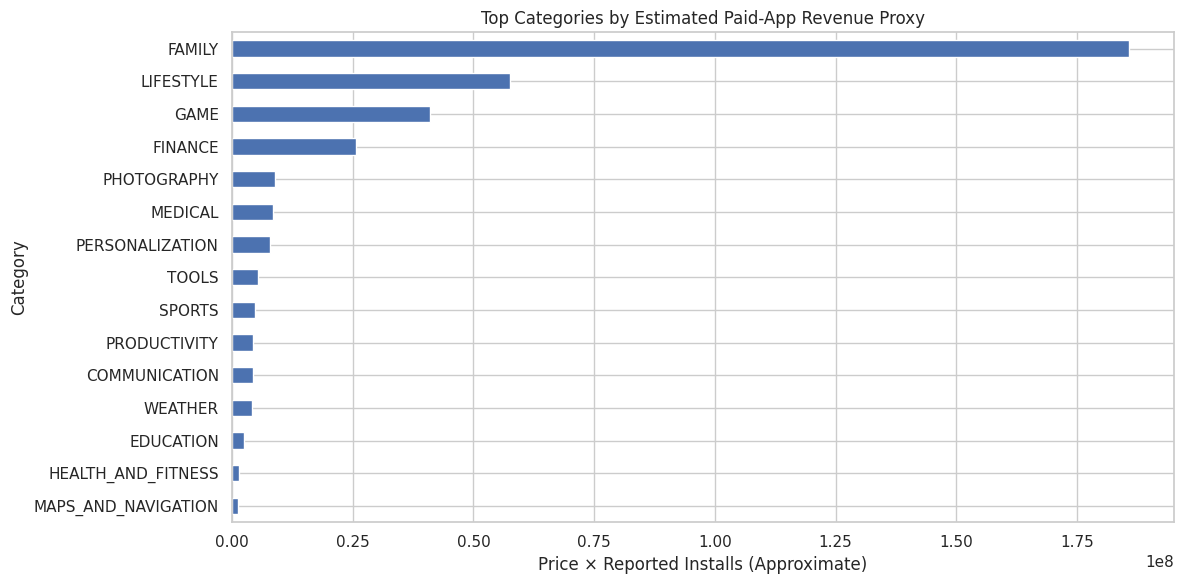

In [28]:
revenue_df = apps_df[
    (apps_df["Type"] == "Paid") &
    (apps_df["Price"] > 0) &
    (apps_df["Installs"] >= 0)
].copy()

revenue_df["Estimated_Revenue"] = (
    revenue_df["Price"] * revenue_df["Installs"]
)

revenue_by_category = (
    revenue_df.groupby("Category")["Estimated_Revenue"]
    .agg(["sum", "median", "count"])
    .sort_values("sum", ascending=False)
)

revenue_by_category.columns = [
    "Estimated Revenue Proxy",
    "Median App Estimate",
    "Paid App Count"
]

print("Top categories by estimated revenue proxy:")
display(revenue_by_category.head(15).round(2))

plt.figure(figsize=(12, 6))
revenue_by_category["Estimated Revenue Proxy"].head(15).sort_values().plot(
    kind="barh"
)
plt.title("Top Categories by Estimated Paid-App Revenue Proxy")
plt.xlabel("Price × Reported Installs (Approximate)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

13. ANALYSING USER REVIEW SENTIMENTS

Review columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']

Sentiment counts:


,Count
Sentiment,
Positive,19015
Negative,6321
Neutral,4361
NaN,982


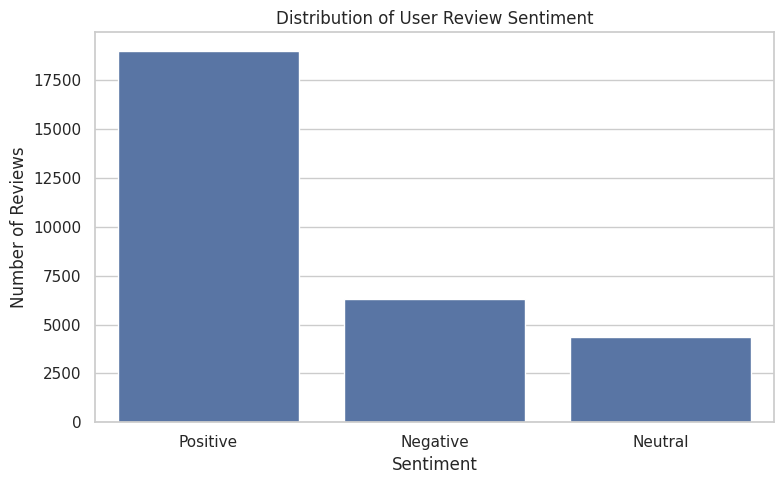

Usable reviews after cleaning: 29692


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
4,10 Best Foods for You,Best idea us,Positive,1.00,0.30
5,10 Best Foods for You,Best way,Positive,1.00,0.30


Reviews matched to app categories: 28250
Categories with the highest positive-review share:


Sentiment,Positive,Neutral,Negative
Category,,,
COMICS,86.67,11.11,2.22
AUTO_AND_VEHICLES,81.27,12.72,6.01
EVENTS,78.85,10.90,10.26
HEALTH_AND_FITNESS,77.85,11.17,10.98
EDUCATION,75.78,12.58,11.65
FOOD_AND_DRINK,74.10,12.52,13.38
LIBRARIES_AND_DEMO,71.39,13.25,15.36
PARENTING,70.70,20.31,8.98
WEATHER,69.59,15.98,14.43


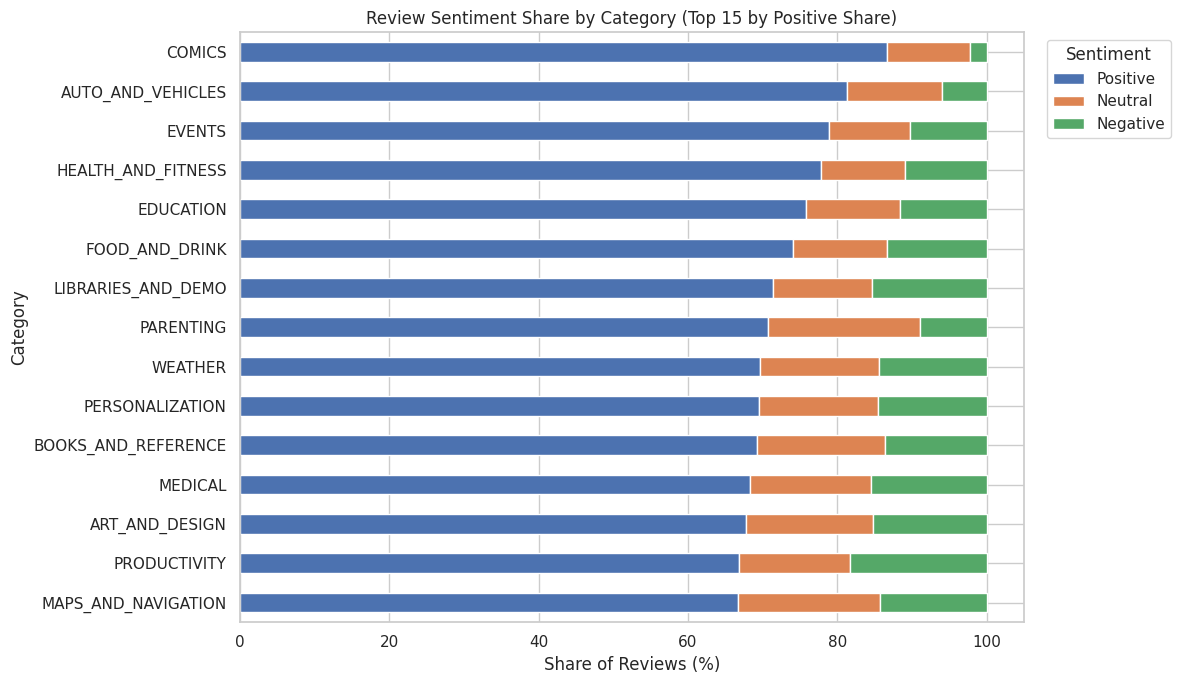

In [29]:
print("Review columns:")
print(reviews_df.columns.tolist())

print("\nSentiment counts:")
display(reviews_df["Sentiment"].value_counts(dropna=False).to_frame("Count"))

plt.figure(figsize=(8, 5))
sns.countplot(
    data=reviews_df,
    x="Sentiment",
    order=reviews_df["Sentiment"].value_counts().index
)
plt.title("Distribution of User Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Remove rows without usable review text or sentiment
reviews_clean = reviews_df.dropna(
    subset=["Translated_Review", "Sentiment"]
).copy()

reviews_clean["Translated_Review"] = (
    reviews_clean["Translated_Review"].astype(str).str.strip()
)

reviews_clean["Sentiment"] = (
    reviews_clean["Sentiment"].astype(str).str.strip().str.title()
)

reviews_clean = reviews_clean[
    reviews_clean["Translated_Review"].ne("") &
    reviews_clean["Sentiment"].isin(["Positive", "Neutral", "Negative"])
].copy()

print("Usable reviews after cleaning:", len(reviews_clean))
display(reviews_clean.head())

app_category_lookup = (
    apps_df[["App", "Category"]]
    .dropna()
    .drop_duplicates(subset=["App"])
)

reviews_with_category = reviews_clean.merge(
    app_category_lookup,
    on="App",
    how="inner"
)

print("Reviews matched to app categories:", len(reviews_with_category))

sentiment_by_category = pd.crosstab(
    reviews_with_category["Category"],
    reviews_with_category["Sentiment"],
    normalize="index"
) * 100

# Make sure all sentiment columns are available
for col in ["Positive", "Neutral", "Negative"]:
    if col not in sentiment_by_category.columns:
        sentiment_by_category[col] = 0

sentiment_by_category = sentiment_by_category[
    ["Positive", "Neutral", "Negative"]
]

# Sort categories by positive review share
sentiment_by_category = sentiment_by_category.sort_values(
    "Positive", ascending=False
)

print("Categories with the highest positive-review share:")
display(sentiment_by_category.head(15).round(2))

sentiment_by_category.head(15).sort_values("Positive").plot(
    kind="barh", stacked=True, figsize=(12, 7)
)
plt.title("Review Sentiment Share by Category (Top 15 by Positive Share)")
plt.xlabel("Share of Reviews (%)")
plt.ylabel("Category")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

14. ADDITIONAL VISUALISATION

In [30]:
interactive_df = apps_df.dropna(
    subset=["Rating", "Installs", "Category"]
).copy()

interactive_df = interactive_df[
    interactive_df["Installs"] > 0
]

# Limit to the most-installed apps for a manageable chart
plot_df = interactive_df.nlargest(1000, "Installs")

fig = px.scatter(
    plot_df,
    x="Rating",
    y="Installs",
    color="Category",
    hover_name="App",
    hover_data=["Type", "Price", "Reviews"],
    log_y=True,
    title="Interactive App Ratings vs Installs",
    labels={
        "Rating": "Rating (out of 5)",
        "Installs": "Reported Installs (log scale)"
    }
)

fig.show()

15. KEY INSIGHTS

In [31]:
# Insight 1: Most common category
top_category = apps_df["Category"].value_counts().idxmax()
top_category_count = apps_df["Category"].value_counts().max()
top_category_pct = top_category_count / len(apps_df) * 100

# Insight 2: Free vs paid ratings
rating_comparison = (
    apps_df[apps_df["Type"].isin(["Free", "Paid"])]
    .groupby("Type")["Rating"]
    .mean()
)

# Insight 3: Overall review sentiment proportions
sentiment_share = (
    reviews_clean["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
)

print("THREE DATA-BASED FINDINGS")
print("-" * 55)

print(
    f"1. Most represented category: {top_category}, "
    f"with {top_category_count:,} rows "
    f"({top_category_pct:.1f}% of cleaned app records)."
)

if "Free" in rating_comparison and "Paid" in rating_comparison:
    print(
        f"2. Average rating: free apps = {rating_comparison['Free']:.2f}, "
        f"paid apps = {rating_comparison['Paid']:.2f}. "
        "This is a descriptive comparison, not evidence of causation."
    )
else:
    print("2. Not enough free/paid rating data for a comparison.")

if not sentiment_share.empty:
    print(
        f"3. The most common sentiment among usable reviews is "
        f"{sentiment_share.idxmax()}, at "
        f"{sentiment_share.max():.1f}% of usable reviews."
    )

THREE DATA-BASED FINDINGS
-------------------------------------------------------
1. Most represented category: FAMILY, with 1,943 rows (18.8% of cleaned app records).
2. Average rating: free apps = 4.18, paid apps = 4.26. This is a descriptive comparison, not evidence of causation.
3. The most common sentiment among usable reviews is Positive, at 64.0% of usable reviews.


In [32]:
# FINAL CONCLUSION WITH YOUR ACTUAL RESULTS
# Run after the data-cleaning and analysis cells.

# 1. Most represented category
category_counts = apps_df["Category"].value_counts()
top_category = category_counts.index[0]
top_category_count = int(category_counts.iloc[0])
top_category_pct = top_category_count / len(apps_df) * 100

# 2. Highest-rated category with at least 20 rated apps
category_ratings = (
    apps_df.groupby("Category")["Rating"]
    .agg(["mean", "count"])
)
reliable_categories = category_ratings[
    category_ratings["count"] >= 20
].sort_values("mean", ascending=False)

if not reliable_categories.empty:
    best_rated_category = reliable_categories.index[0]
    best_rating = reliable_categories.iloc[0]["mean"]
    best_rating_count = int(reliable_categories.iloc[0]["count"])
else:
    best_rated_category = "Not enough data"
    best_rating = np.nan
    best_rating_count = 0

# 3. App size vs installs: Spearman correlation
size_installs = apps_df.dropna(
    subset=["Size_MB", "Installs"]
)
size_installs = size_installs[
    (size_installs["Size_MB"] > 0) &
    (size_installs["Installs"] > 0)
]
correlation = size_installs["Size_MB"].corr(
    size_installs["Installs"], method="spearman"
)

if pd.isna(correlation):
    correlation_strength = "could not be calculated"
elif abs(correlation) < 0.30:
    correlation_strength = "weak"
elif abs(correlation) < 0.60:
    correlation_strength = "moderate"
else:
    correlation_strength = "strong"

if pd.notna(correlation) and correlation < 0:
    correlation_direction = "negative"
else:
    correlation_direction = "positive"

# 4. Free vs paid average ratings
rating_comparison = (
    apps_df[apps_df["Type"].isin(["Free", "Paid"])]
    .groupby("Type")["Rating"]
    .mean()
)

free_rating = rating_comparison.get("Free", np.nan)
paid_rating = rating_comparison.get("Paid", np.nan)

# 5. Estimated paid-app revenue proxy by category
paid_apps = apps_df[
    (apps_df["Type"] == "Paid") &
    (apps_df["Price"] > 0) &
    apps_df["Installs"].notna()
].copy()

paid_apps["Estimated_Revenue"] = (
    paid_apps["Price"] * paid_apps["Installs"]
)

revenue_by_category = paid_apps.groupby(
    "Category"
)["Estimated_Revenue"].sum().sort_values(ascending=False)

if not revenue_by_category.empty:
    top_revenue_category = revenue_by_category.index[0]
    top_revenue_value = revenue_by_category.iloc[0]
else:
    top_revenue_category = "Not available"
    top_revenue_value = np.nan

# 6. Most common sentiment among usable reviews
# Rebuild cleaned review subset to make this cell more robust.
review_text_col = "Translated_Review"
if review_text_col in reviews_df.columns and "Sentiment" in reviews_df.columns:
    usable_reviews = reviews_df.dropna(
        subset=[review_text_col, "Sentiment"]
    ).copy()

    usable_reviews["Sentiment"] = (
        usable_reviews["Sentiment"].astype(str).str.strip().str.title()
    )
    usable_reviews[review_text_col] = (
        usable_reviews[review_text_col].astype(str).str.strip()
    )

    usable_reviews = usable_reviews[
        usable_reviews[review_text_col].ne("") &
        usable_reviews["Sentiment"].isin(
            ["Positive", "Neutral", "Negative"]
        )
    ]

    sentiment_pct = (
        usable_reviews["Sentiment"].value_counts(normalize=True) * 100
    )
else:
    sentiment_pct = pd.Series(dtype=float)

if not sentiment_pct.empty:
    most_common_sentiment = sentiment_pct.idxmax()
    most_common_sentiment_pct = sentiment_pct.max()
    usable_review_count = int(sentiment_pct.sum() * len(usable_reviews))
else:
    most_common_sentiment = "Not available"
    most_common_sentiment_pct = np.nan
    usable_review_count = 0

# Format values safely
def fmt(value, decimals=2):
    return f"{value:,.{decimals}f}" if pd.notna(value) else "not available"

# Print the completed report
conclusion = f"""
# Google Play Store Analysis — Conclusion

The analysis explored app categories, user ratings, app size, installs,
pricing, estimated paid-app revenue, and user review sentiment using
the Google Play Store dataset from Kaggle.

## Key findings

1. **Category distribution:** The most represented category was
   **{top_category}**, with **{top_category_count:,} app records**
   ({top_category_pct:.2f}% of the {len(apps_df):,} cleaned app records).
   This indicates strong representation in the dataset, although app
   count alone does not establish market demand or profitability.

2. **Ratings:** The highest average rating among categories with at
   least 20 rated apps was **{best_rated_category}**, at
   **{fmt(best_rating)}/5**, based on {best_rating_count:,} rated apps.
   Ratings should be interpreted alongside the number of apps
   contributing to each average.

3. **App size and installs:** The Spearman correlation was
   **{fmt(correlation, 3)}**, indicating a **{correlation_strength}
   {correlation_direction} association** between app size and installs
   in this sample. This does not establish that app size causes changes
   in installs.

4. **Free versus paid apps:** The average rating was
   **{fmt(free_rating)}/5 for free apps** and
   **{fmt(paid_rating)}/5 for paid apps**. This comparison is descriptive
   and may be affected by differences in category, audience, and other
   factors.

5. **Pricing and estimated revenue:** The category with the highest
   estimated paid-app revenue proxy was **{top_revenue_category}**,
   with a price-times-reported-installs estimate of
   **${fmt(top_revenue_value)}**. This is a rough proxy, not verified
   revenue or profit.

6. **Review sentiment:** The most common sentiment among usable reviews
   was **{most_common_sentiment}**, representing
   **{fmt(most_common_sentiment_pct, 2)}%** of
   **{usable_review_count:,} usable reviews**. These reviews may not
   represent the opinions of all app users.

## Recommendations for developers

- Research categories with promising ratings and sufficient app coverage
  before selecting a market.
- Prioritize improvements supported by review sentiment and recurring
  user feedback.
- Evaluate pricing alongside installs, ratings, and category context
  rather than assuming paid apps are inherently better.
- Validate these findings using more recent and representative data
  before making business decisions.

## Limitations

The dataset contains missing values, duplicate records, and some
malformed entries. Install counts are reported as approximate buckets,
and the review dataset does not cover every app or every user.
Therefore, the findings describe this dataset and should not be
interpreted as causal claims or exact measurements of current Google
Play Store performance.
"""

print(conclusion)



# Google Play Store Analysis — Conclusion

The analysis explored app categories, user ratings, app size, installs,
pricing, estimated paid-app revenue, and user review sentiment using
the Google Play Store dataset from Kaggle.

## Key findings

1. **Category distribution:** The most represented category was
   **FAMILY**, with **1,943 app records**
   (18.76% of the 10,358 cleaned app records).
   This indicates strong representation in the dataset, although app
   count alone does not establish market demand or profitability.

2. **Ratings:** The highest average rating among categories with at
   least 20 rated apps was **EVENTS**, at
   **4.44/5**, based on 45 rated apps.
   Ratings should be interpreted alongside the number of apps
   contributing to each average.

3. **App size and installs:** The Spearman correlation was
   **0.342**, indicating a **moderate
   positive association** between app size and installs
   in this sample. This does not establish that app size causes cha